# Analyse des données

In [221]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [222]:
dataset = pd.read_csv('../data/rafined/dataset.csv', sep=',', na_values=[''], quotechar='"')

## Généralités sur le dataset

In [223]:
dataset.head(5)

,Area,Item,Year,hg/ha,Area ISO Code,Area ISO Alpha-2 Code,Area ISO Alpha-3 Code,Code,average_rain_fall_mm_per_year,pesticides_tonnes,pesticides_kg_ha,avg_temp,missing_pesticide_value,missing_rain_value,missing_temp_value
0,Afghanistan,Maïs,1990,17582,4,AF,AFG,AFG,389.80063,NaN,NaN,15.45,1,0,0
1,Afghanistan,Maïs,1991,16800,4,AF,AFG,AFG,522.01180,NaN,NaN,14.57,1,0,0
2,Afghanistan,Maïs,1992,15000,4,AF,AFG,AFG,483.13354,NaN,NaN,14.35,1,0,0
3,Afghanistan,Maïs,1993,16786,4,AF,AFG,AFG,352.79886,NaN,NaN,14.96,1,0,0
4,Afghanistan,Maïs,1994,16667,4,AF,AFG,AFG,375.86728,NaN,NaN,14.94,1,0,0


In [224]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 25848 entries, 0 to 25847
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Area                           25848 non-null  str    
 1   Item                           25848 non-null  str    
 2   Year                           25848 non-null  int64  
 3   hg/ha                          25848 non-null  int64  
 4   Area ISO Code                  25848 non-null  int64  
 5   Area ISO Alpha-2 Code          25580 non-null  str    
 6   Area ISO Alpha-3 Code          25666 non-null  str    
 7   Code                           23850 non-null  str    
 8   average_rain_fall_mm_per_year  24032 non-null  float64
 9   pesticides_tonnes              24618 non-null  float64
 10  pesticides_kg_ha               24402 non-null  float64
 11  avg_temp                       18674 non-null  float64
 12  missing_pesticide_value        25848 non-null  int64  
 1

In [225]:
print(f'Le dataset couvre les années de {dataset['Year'].min()} à {dataset['Year'].max()}')
print(f'Nombre de pays couverts : {dataset['Area'].nunique()}')
print(f'Nombre de cultures couvertes : {dataset['Item'].nunique()}')

print(f'Total : {len(dataset)} lignes.')

Le dataset couvre les années de 1990 à 2013
Nombre de pays couverts : 211
Nombre de cultures couvertes : 10
Total : 25848 lignes.


In [226]:
dataset.isnull().sum()

Area                                0
Item                                0
Year                                0
hg/ha                               0
Area ISO Code                       0
Area ISO Alpha-2 Code             268
Area ISO Alpha-3 Code             182
Code                             1998
average_rain_fall_mm_per_year    1816
pesticides_tonnes                1230
pesticides_kg_ha                 1446
avg_temp                         7174
missing_pesticide_value             0
missing_rain_value                  0
missing_temp_value                  0
dtype: int64

In [227]:
# TODO : analyser la structure des valeurs manquantes
#  - taux de NaN par année et par variable (heatmap Year x variable)
#  - liste des pays sans aucune température (74 pays)
#  - en déduire la stratégie : suppression, imputation (par pays ? par région ?) ou indicateur missing_*


## Analyse de variable cible : rendement

In [228]:
dataset['hg/ha'].describe()

count     25848.000000
mean      68320.437790
std       74128.509505
min           0.000000
25%       18000.750000
50%       39582.000000
75%       94562.500000
max      554855.000000
Name: hg/ha, dtype: float64

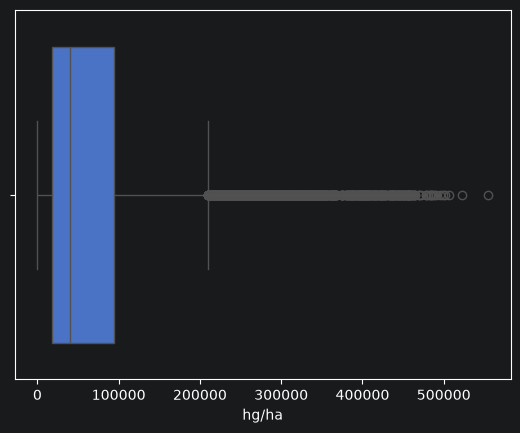

In [229]:
sns.boxplot(x=dataset['hg/ha'])
plt.show()

In [230]:
dataset[dataset['hg/ha'] == 0]

,Area,Item,Year,hg/ha,Area ISO Code,Area ISO Alpha-2 Code,Area ISO Alpha-3 Code,Code,average_rain_fall_mm_per_year,pesticides_tonnes,pesticides_kg_ha,avg_temp,missing_pesticide_value,missing_rain_value,missing_temp_value
16252,New Caledonia,Sorgho,2000,0,540,NC,NCL,NCL,1413.03170,221.0,20.05,NaN,0,0,1
16254,New Caledonia,Sorgho,2012,0,540,NC,NCL,NCL,1707.17580,249.0,24.32,NaN,0,0,1
16290,New Caledonia,Blé,2000,0,540,NC,NCL,NCL,1413.03170,221.0,20.05,NaN,0,0,1
16292,New Caledonia,Blé,2002,0,540,NC,NCL,NCL,1324.59470,250.0,23.14,NaN,0,0,1
16296,New Caledonia,Blé,2006,0,540,NC,NCL,NCL,1232.40380,235.0,21.73,NaN,0,0,1
16297,New Caledonia,Blé,2007,0,540,NC,NCL,NCL,1273.20830,239.0,22.17,NaN,0,0,1
16298,New Caledonia,Blé,2011,0,540,NC,NCL,NCL,2105.52200,239.0,21.63,NaN,0,0,1
17165,Occupied Palestinian Territory,Sorgho,1999,0,275,PS,PSE,PSE,175.92204,1263.0,7.41,NaN,0,0,1


Un rendement de 0 n'est pas forcément une erreur (récolte nulle une année donnée). Ces 8 lignes concernent des petits territoires (Nouvelle-Calédonie, Palestine) et ne pèsent pas dans l'ensemble : je décide de les conserver.

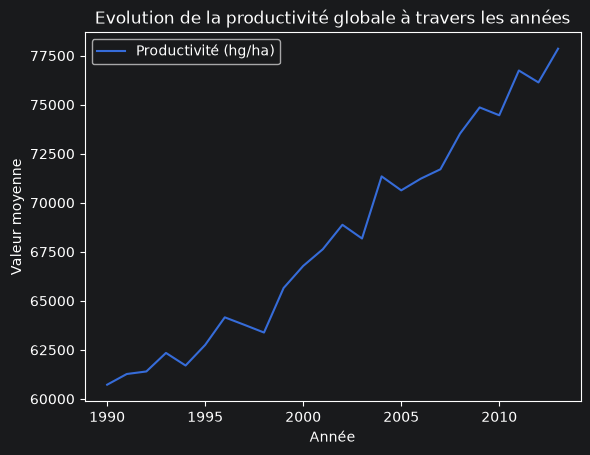

In [231]:
mean_hg_ha = dataset.groupby('Year')['hg/ha'].mean()

plt.plot(mean_hg_ha, label='Productivité (hg/ha)')
plt.xlabel('Année')
plt.ylabel('Valeur moyenne')
plt.title('Evolution de la productivité globale à travers les années')
plt.legend()
plt.show()

Le rendement moyen toutes cultures confondues passe d'environ 60 000 hg/ha en 1990 à 77 500 hg/ha en 2013. La tendance est plutôt régulière, sans rupture marquée.

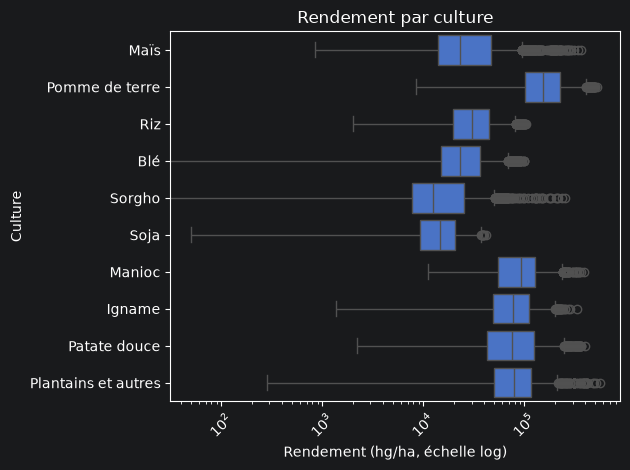

In [232]:
sns.boxplot(data=dataset, y='Item', x='hg/ha')

plt.xscale('log')
plt.title('Rendement par culture')
plt.xlabel('Rendement (hg/ha, échelle log)')
plt.ylabel('Culture')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Les ordres de grandeur sont très différents selon la culture : les tubercules (pommes de terre, manioc, ignames, patates douces) et les plantains dépassent largement les céréales (maïs, blé, riz, sorgho) et le soja. Chaque culture a aussi une forte dispersion entre pays. **La culture est le premier facteur explicatif du rendement.**

Text(0, 0.5, "Nombre d'observations")

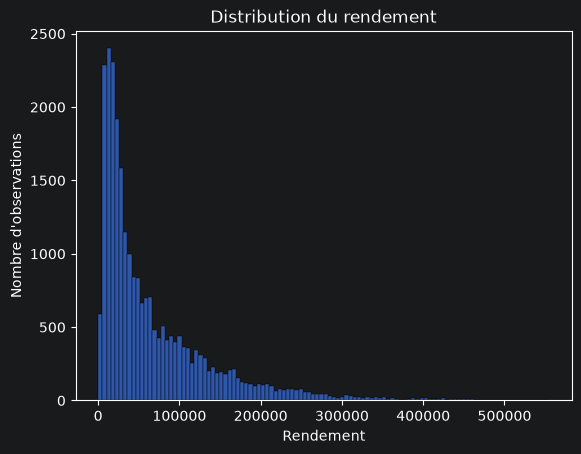

In [233]:
sns.histplot(data=dataset, x='hg/ha')
plt.title('Distribution du rendement')
plt.xlabel('Rendement')
plt.ylabel('Nombre d\'observations')

La distribution est concentrée à gauche avec une longue traîne à droite. Cette traîne n'est **pas** due à des outliers : le boxplot par culture montre que les tubercules (pommes de terre, manioc, ignames, patates douces) et les plantains ont naturellement un rendement environ 5 à 10 fois supérieur aux céréales et au soja. La distribution est en fait un **mélange de cultures aux ordres de grandeur différents**.

<Axes: xlabel='hg/ha', ylabel='Count'>

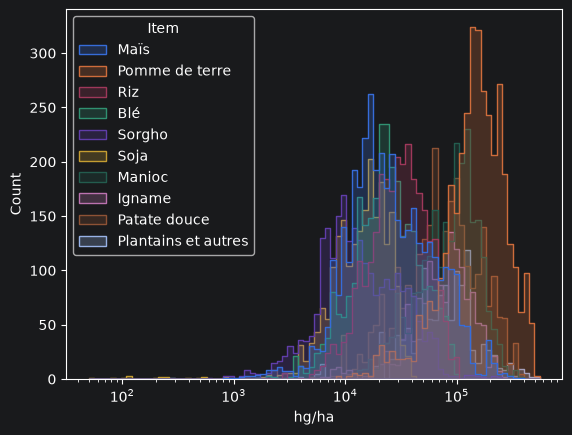

In [234]:
sns.histplot(data=dataset, x='hg/ha', hue='Item', log_scale=True, element='step')


In [235]:
dataset.sort_values(by='hg/ha', ascending=False).head(10)

,Area,Item,Year,hg/ha,Area ISO Code,Area ISO Alpha-2 Code,Area ISO Alpha-3 Code,Code,average_rain_fall_mm_per_year,pesticides_tonnes,pesticides_kg_ha,avg_temp,missing_pesticide_value,missing_rain_value,missing_temp_value
1840,Belize,Plantains et autres,2009,554855,84,BZ,BLZ,BLZ,1348.91920,789.0,7.51,NaN,0,0,1
1760,Belgium-Luxembourg,Pomme de terre,1997,522291,58,NaN,NaN,NaN,137.54272,8307.0,9.34,NaN,0,0,1
1831,Belize,Plantains et autres,2000,507074,84,BZ,BLZ,BLZ,1621.00870,1296.0,13.09,NaN,0,0,1
1726,Belgium,Pomme de terre,2011,501412,56,BE,BEL,BEL,788.48303,6297.0,7.44,11.69,0,0,0
1756,Belgium-Luxembourg,Pomme de terre,1993,499376,58,NaN,NaN,NaN,142.96341,9074.0,10.56,NaN,0,0,1
16369,New Zealand,Pomme de terre,2010,495751,554,NZ,NZL,NZL,1631.82450,5285.0,9.27,13.54,0,0,0
16370,New Zealand,Pomme de terre,2011,490361,554,NZ,NZL,NZL,1599.82170,5285.0,9.75,13.46,0,0,0
1826,Belize,Plantains et autres,1995,488289,84,BZ,BLZ,BLZ,1575.00650,1180.0,12.29,NaN,0,0,1
22280,Switzerland,Pomme de terre,1996,487219,756,CH,CHE,CHE,1586.61510,1746.0,3.94,6.66,0,0,0
16371,New Zealand,Pomme de terre,2012,484810,554,NZ,NZL,NZL,1516.80140,5285.0,9.11,12.89,0,0,0


Les rendements les plus élevés sont des pommes de terre dans des pays tempérés et développés (Belgique, Nouvelle-Zélande, Suisse) et des plantains au Belize. Ces valeurs sont cohérentes agronomiquement : ce ne sont pas des erreurs de saisie.

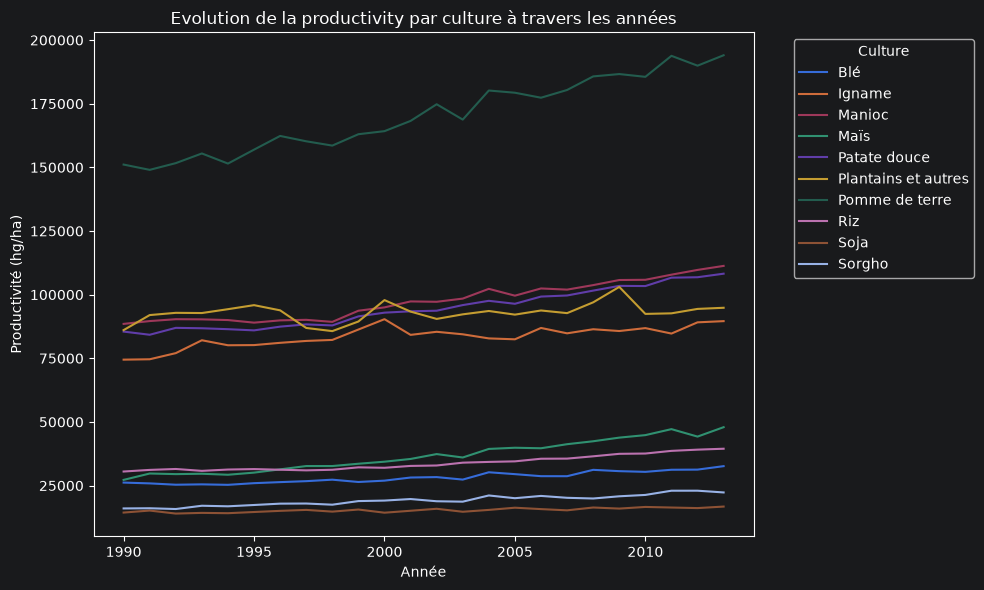

In [237]:
plt.figure(figsize=(10, 6))

for item, group in dataset.groupby('Item'):
    item_data = group.groupby('Year')['hg/ha'].mean()
    plt.plot(item_data.index, item_data.values, label=item)

plt.xlabel('Année')
plt.ylabel('Productivité (hg/ha)')
plt.title('Evolution de la productivity par culture à travers les années')
plt.legend(title='Culture', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Toutes les cultures voient leur rendement moyen augmenter entre 1990 et 2013, mais pas à la même vitesse.

## Analyse des différentes features

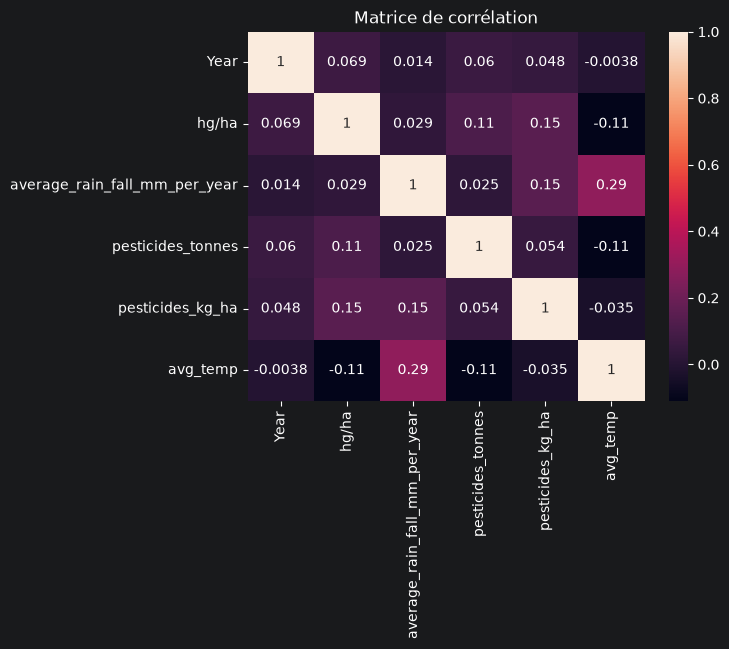

In [238]:
dataset_transformed = dataset.copy()
dataset_transformed['hg/ha'] = np.log1p(dataset['hg/ha'])
corr_matrix = dataset_transformed[['Year', 'hg/ha', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'pesticides_kg_ha', 'avg_temp']].corr()

sns.heatmap(corr_matrix, annot=True)
plt.title('Matrice de corrélation')
plt.show()

Sur l'ensemble du dataset, les corrélations linéaires avec le log du rendement sont **faibles** (pesticides ≈ 0.11-0.15, température ≈ -0.11, précipitations ≈ 0.03). `pesticides_tonnes` et `pesticides_kg_ha` sont corrélées entre elles et redondantes. Ces faibles valeurs s'expliquent en partie par le mélange des cultures.

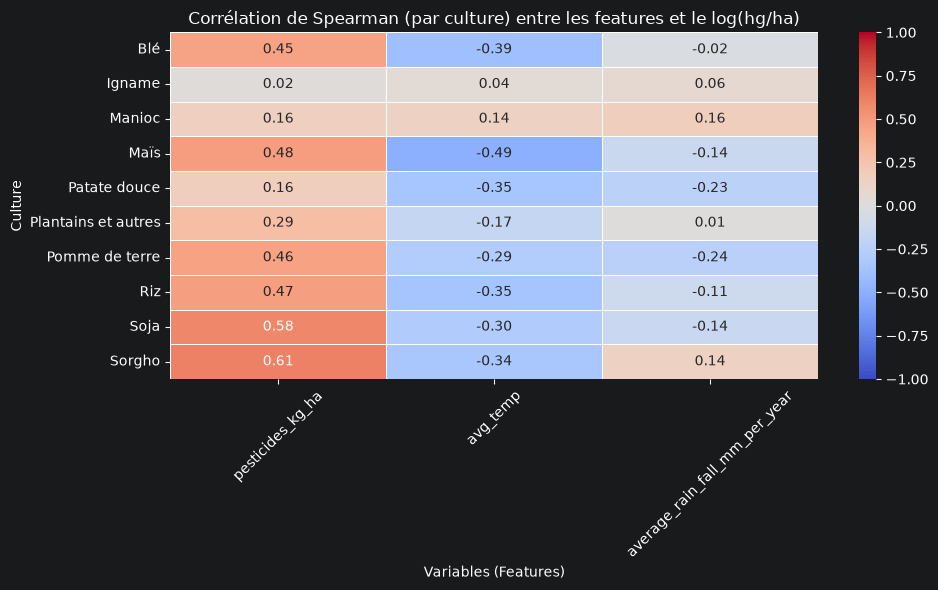

In [259]:
dataset_transformed = dataset.copy()
dataset_transformed['log_hg_ha'] = np.log1p(dataset_transformed['hg/ha'])

features = ['pesticides_kg_ha', 'avg_temp', 'average_rain_fall_mm_per_year']

corr_matrix = (
    dataset_transformed.groupby('Item')[features + ['log_hg_ha']]
    .corr(method='spearman')
    .xs('log_hg_ha', level=1)[features]
)

plt.figure(figsize=(10, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
)

plt.title(
    "Corrélation de Spearman (par culture) entre les features et le log(hg/ha)"
)
plt.xlabel('Variables (Features)')
plt.ylabel('Culture')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### Pesticides

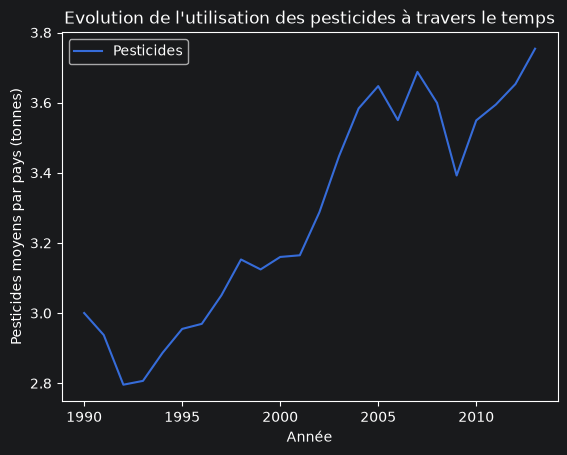

In [260]:
mean_pesticides = dataset.groupby('Year')['pesticides_kg_ha'].mean()

plt.plot(mean_pesticides, label='Pesticides')
plt.xlabel('Année')
plt.ylabel('Pesticides moyens par pays (kg/ha)')
plt.title('Evolution de l\'utilisation des pesticides à travers le temps')
plt.legend()
plt.show()

L'utilisation moyenne de pesticides par pays augmente nettement sur la période : de 2,8 kg/ha en 1990 à 3,8 kg/ha en 2013.

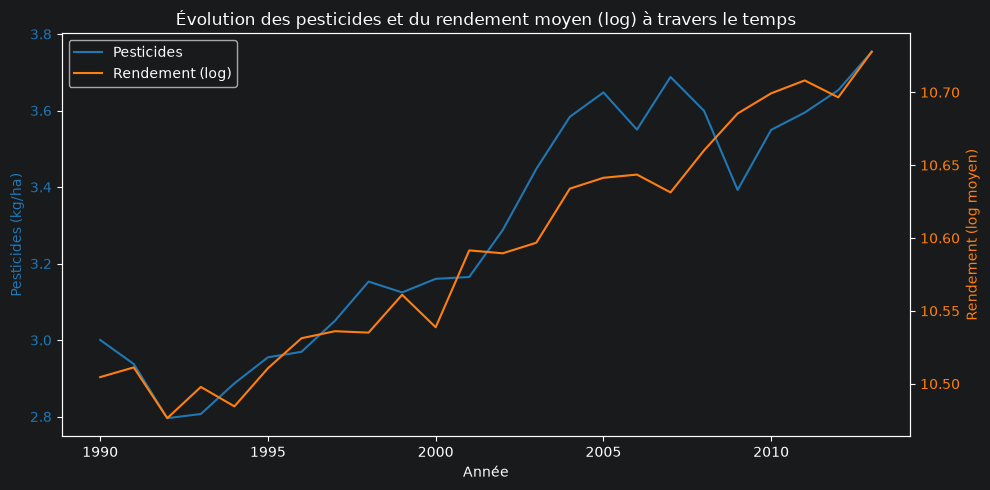

In [269]:
b = dataset.copy()
b['log_hg_ha'] = np.log1p(dataset['hg/ha'])

mean_pesticides = b.groupby('Year')['pesticides_kg_ha'].mean()
mean_log_hg_ha = b.groupby('Year')['log_hg_ha'].mean()

fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Année')
ax1.set_ylabel('Pesticides (kg/ha)', color=color)
(l1,) = ax1.plot(
    mean_pesticides.index,
    mean_pesticides.values,
    color=color,
    label='Pesticides',
)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Rendement (log moyen)', color=color)
(l2,) = ax2.plot(
    mean_log_hg_ha.index,
    mean_log_hg_ha.values,
    color=color,
    label='Rendement (log)',
)
ax2.tick_params(axis='y', labelcolor=color)

lines = [l1, l2]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels)

plt.title("Évolution des pesticides et du rendement moyen (log) à travers le temps")
plt.tight_layout()
plt.show()

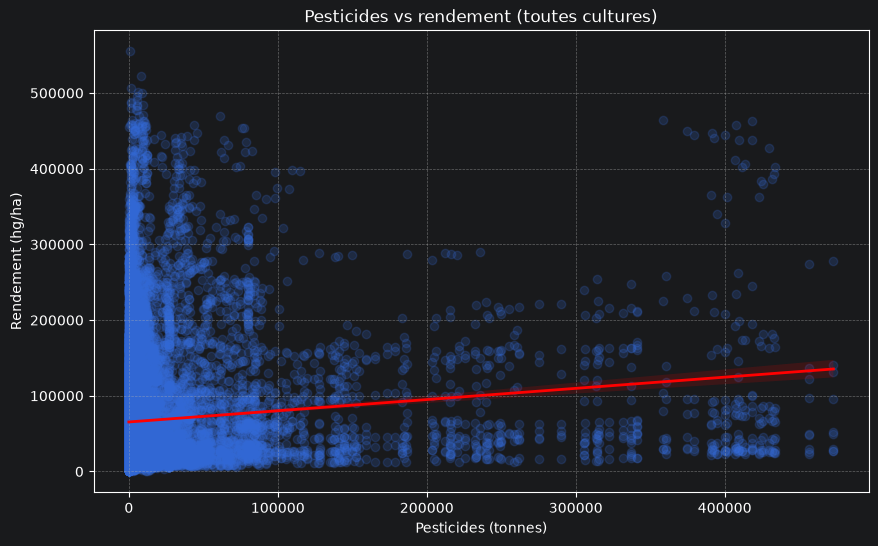

In [243]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data=dataset,
    x='pesticides_tonnes',
    y='hg/ha',
    scatter_kws={'alpha': 0.2},
    line_kws={'color': 'red', 'linewidth': 2},
)

plt.title('Pesticides vs rendement (toutes cultures)')
plt.xlabel('Pesticides (tonnes)')
plt.ylabel('Rendement (hg/ha)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

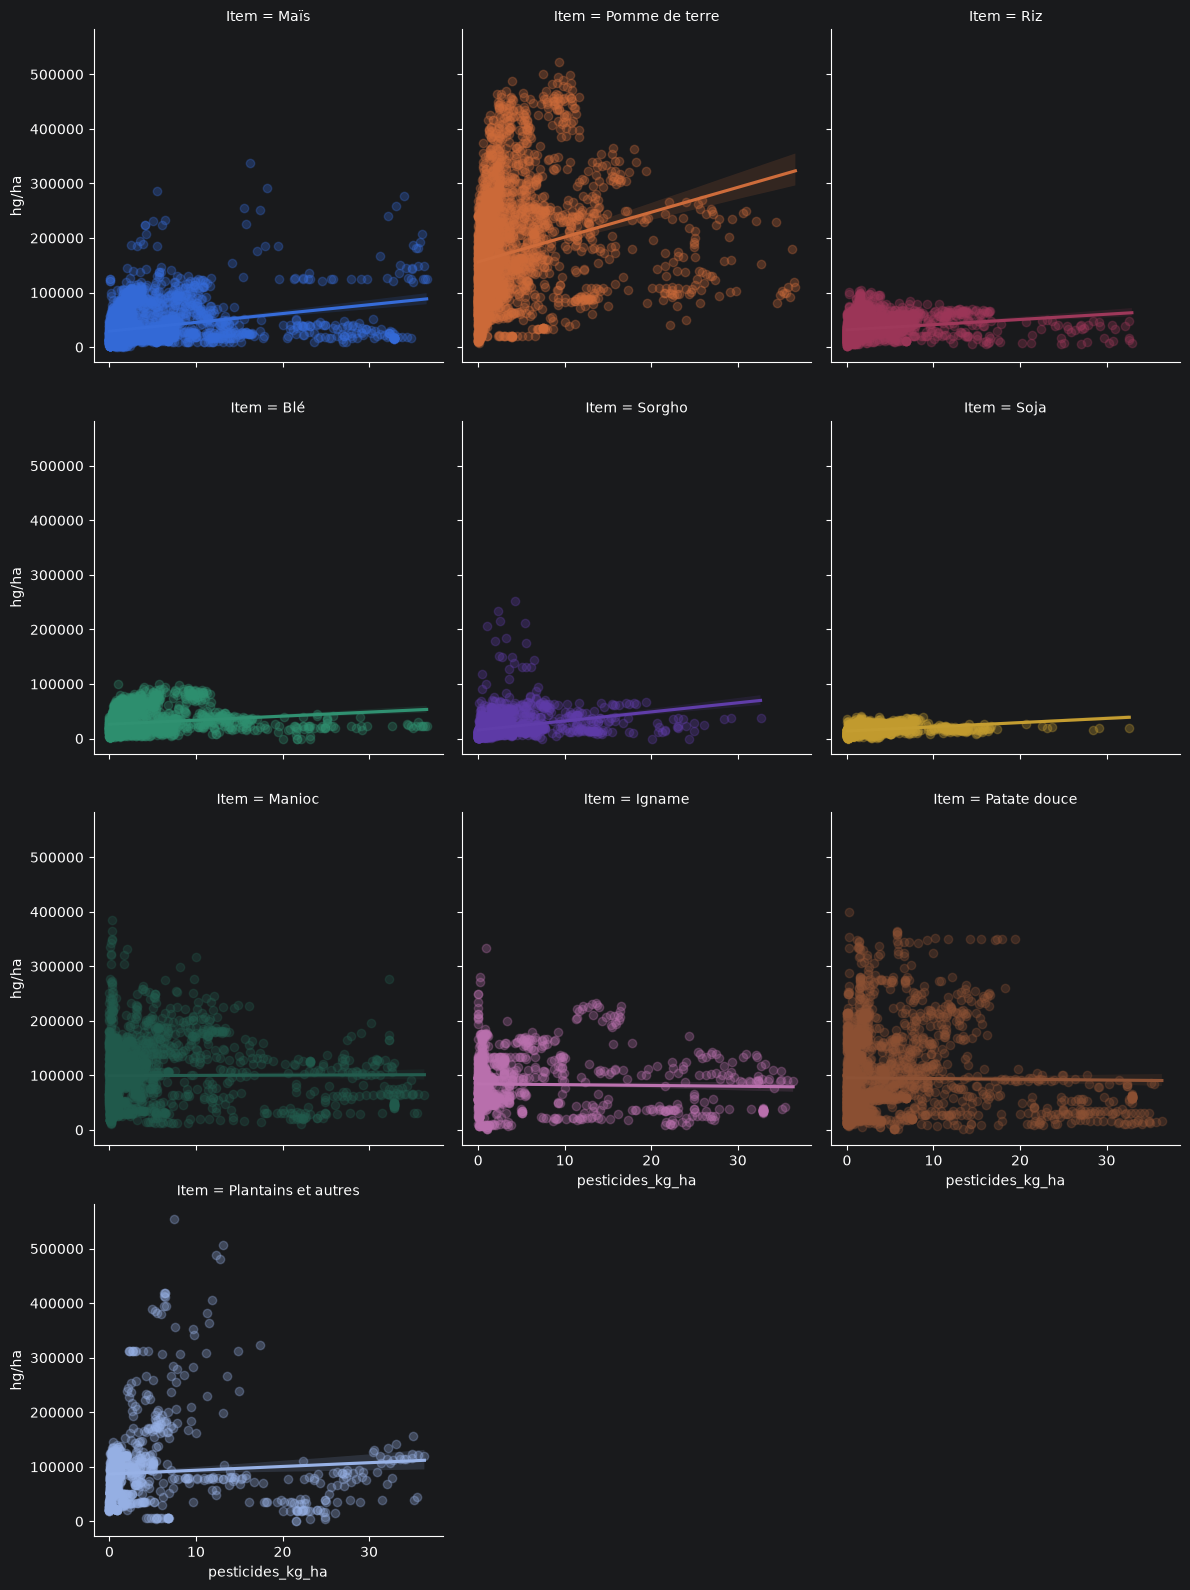

In [244]:
# Comparer les cultures côte à côte
sns.lmplot(
    data=dataset,
    x='pesticides_kg_ha',
    y='hg/ha',
    hue='Item',
    col='Item',
    col_wrap=3,
    height=4,
    scatter_kws={'alpha': 0.3},
)
plt.show()

Sur l'ensemble des cultures, la droite de régression est légèrement croissante mais le nuage est très dispersé. Par culture, la relation positive est plus nette.

### Températures

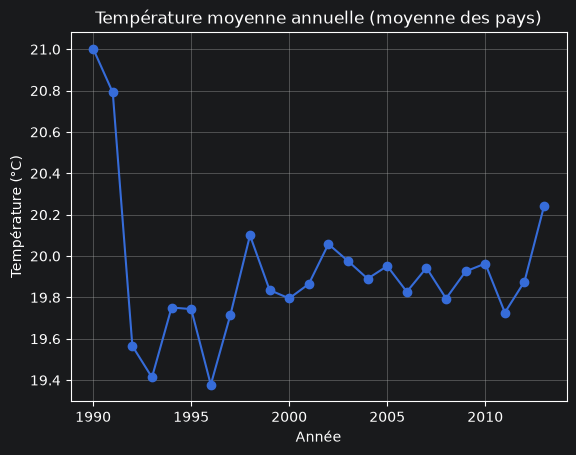

In [245]:
dataset.groupby('Year')['avg_temp'].mean().plot(kind='line', marker='o', grid=True)
plt.title('Température moyenne annuelle (moyenne des pays)')
plt.xlabel('Année')
plt.ylabel('Température (°C)')
plt.show()

La température moyenne varie entre 19,4 et 21 °C selon les années. Ces variations ne traduisent **pas** une évolution climatique : ≈ 28 % des températures sont manquantes (74 pays n'ont aucune valeur), et la moyenne change surtout selon les pays présents chaque année.

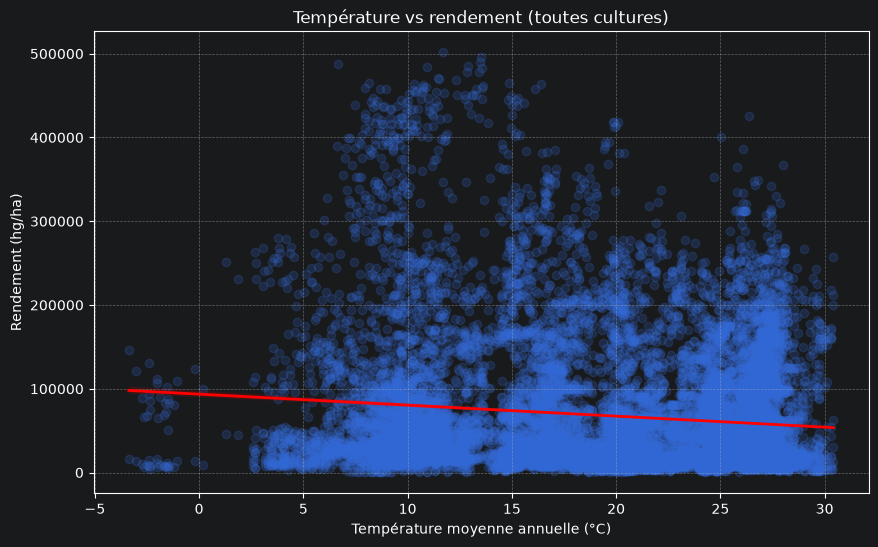

In [246]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data=dataset,
    x='avg_temp',
    y='hg/ha',
    scatter_kws={'alpha': 0.2},
    line_kws={'color': 'red', 'linewidth': 2},
)

plt.title('Température vs rendement (toutes cultures)')
plt.xlabel('Température moyenne annuelle (°C)')
plt.ylabel('Rendement (hg/ha)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

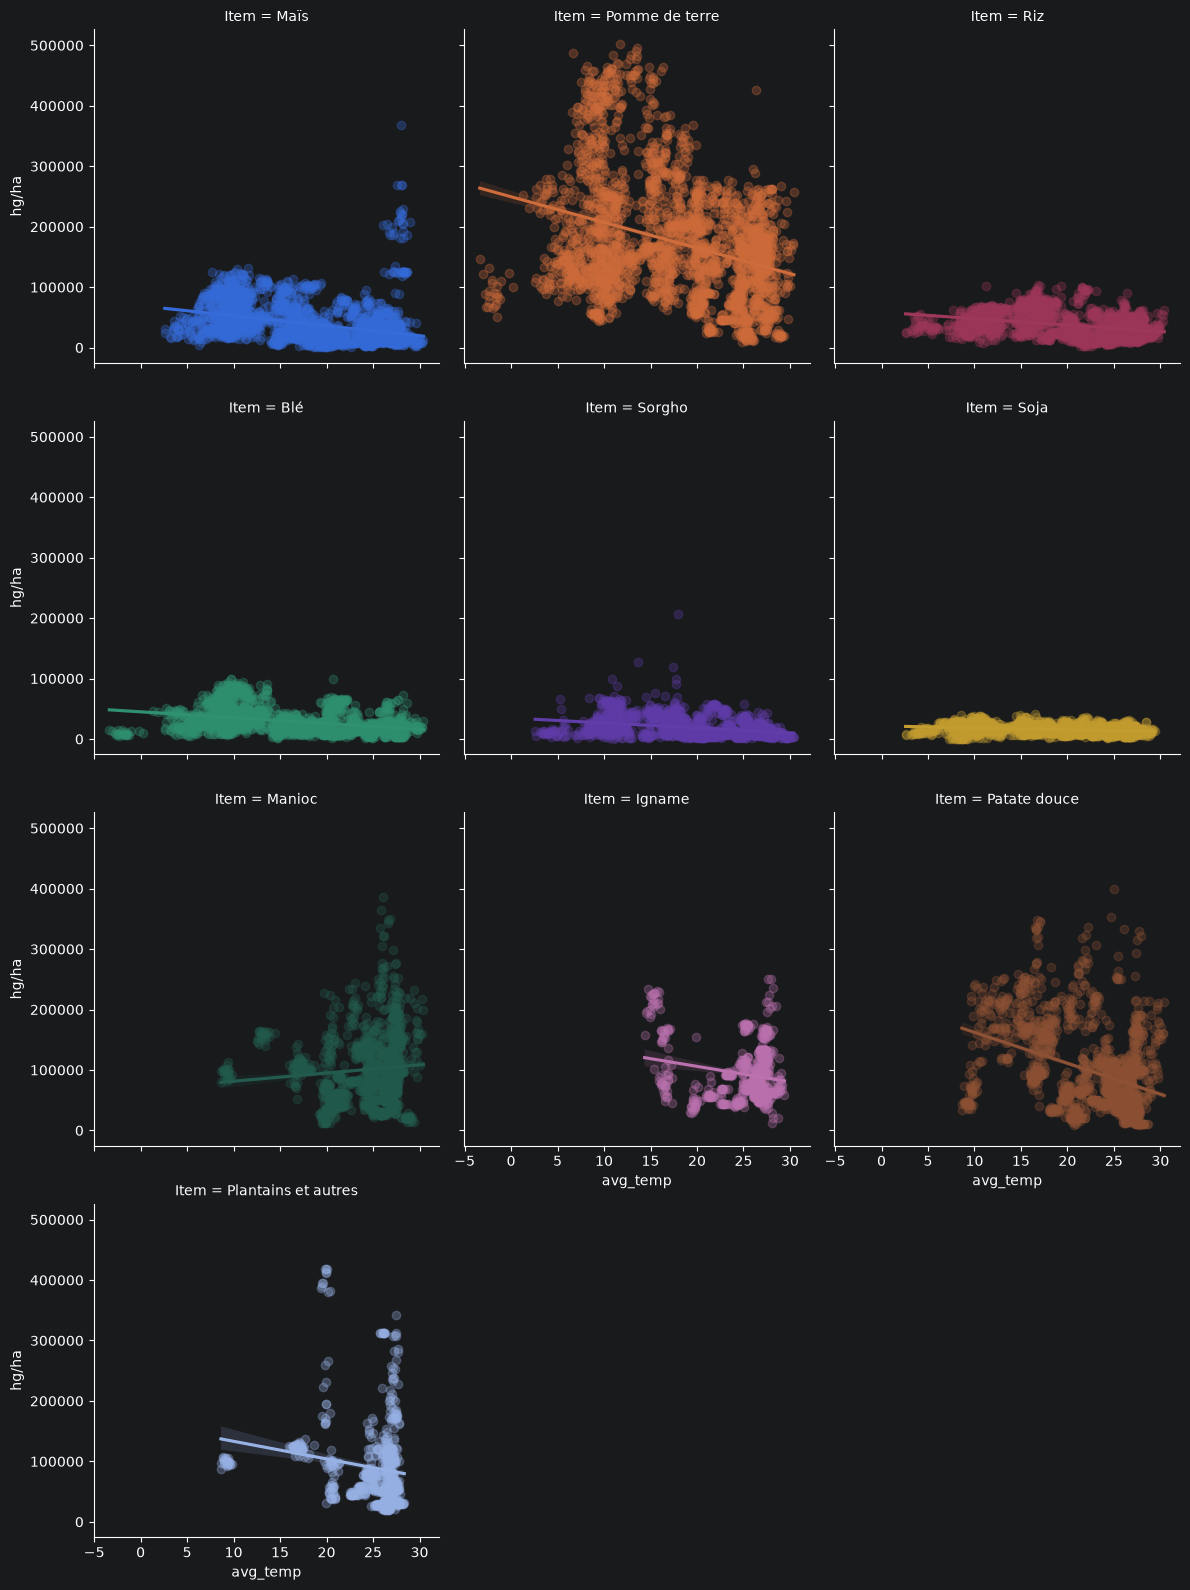

In [247]:
# Comparer les cultures côte à côte
sns.lmplot(
    data=dataset,
    x='avg_temp',
    y='hg/ha',
    hue='Item',
    col='Item',
    col_wrap=3,
    height=4,
    scatter_kws={'alpha': 0.3},
)
plt.show()

Globalement, le rendement baisse légèrement quand la température augmente. Par culture, la relation est négative pour la plupart des cultures (maïs, blé, riz, sorgho) mais positive ou nulle pour le manioc et les ignames, des cultures tropicales. Cela reflète surtout l'opposition entre pays tempérés (productifs en céréales) et tropicaux.

### Précipitations

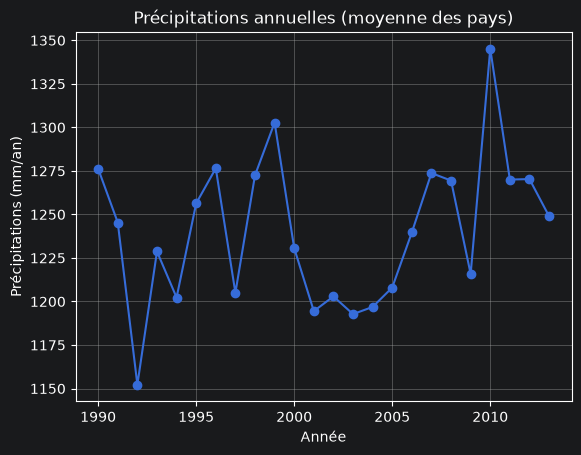

In [249]:
dataset.groupby('Year')['average_rain_fall_mm_per_year'].mean().plot(kind='line', marker='o', grid=True)
plt.title('Précipitations annuelles (moyenne des pays)')
plt.xlabel('Année')
plt.ylabel('Précipitations (mm/an)')
plt.show()

Comme pour la température, les variations de la moyenne annuelle (1 150 à 1 350 mm) reflètent surtout la composition des pays, pas une tendance climatique.

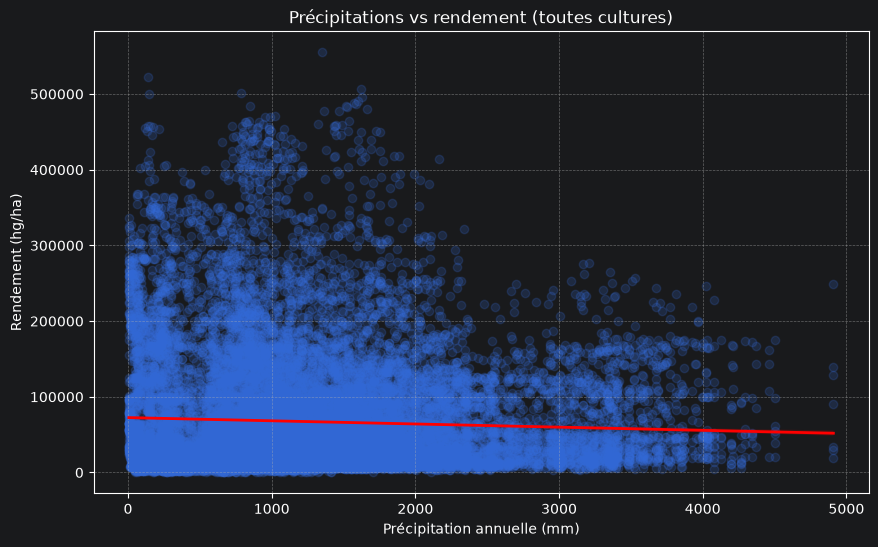

In [250]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data=dataset,
    x='average_rain_fall_mm_per_year',
    y='hg/ha',
    scatter_kws={'alpha': 0.2},  # Transparence pour éviter la surchage des points
    line_kws={'color': 'red', 'linewidth': 2},
)

plt.title('Précipitations vs rendement (toutes cultures)')
plt.xlabel('Précipitation annuelle (mm)')
plt.ylabel('Rendement (hg/ha)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

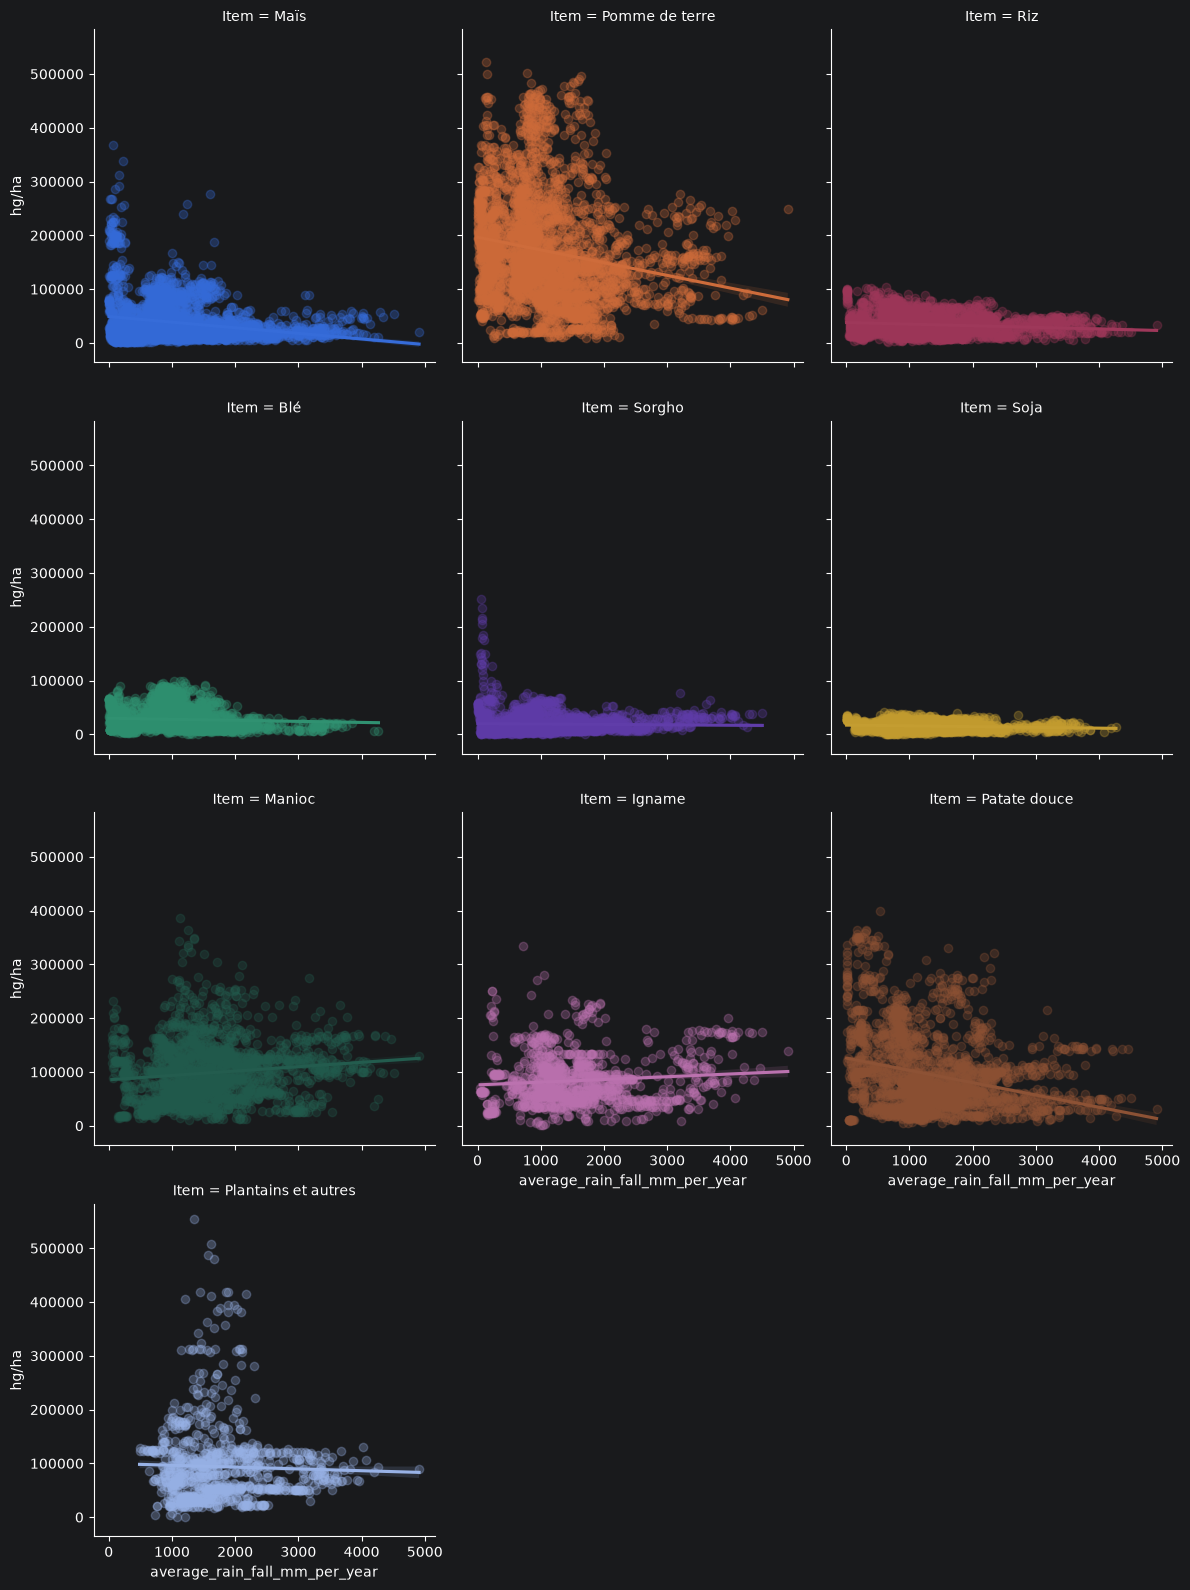

In [251]:
# Comparer les cultures côte à côte
sns.lmplot(
    data=dataset,
    x='average_rain_fall_mm_per_year',
    y='hg/ha',
    hue='Item',
    col='Item',
    col_wrap=3,
    height=4,
    scatter_kws={'alpha': 0.3},
)
plt.show()

Aucune relation globale entre précipitations et rendement. Par culture, l'effet est faible et change de signe : légèrement négatif pour les pommes de terre et les patates douces, légèrement positif pour le manioc et le sorgho.

## Focus sur un pays : France

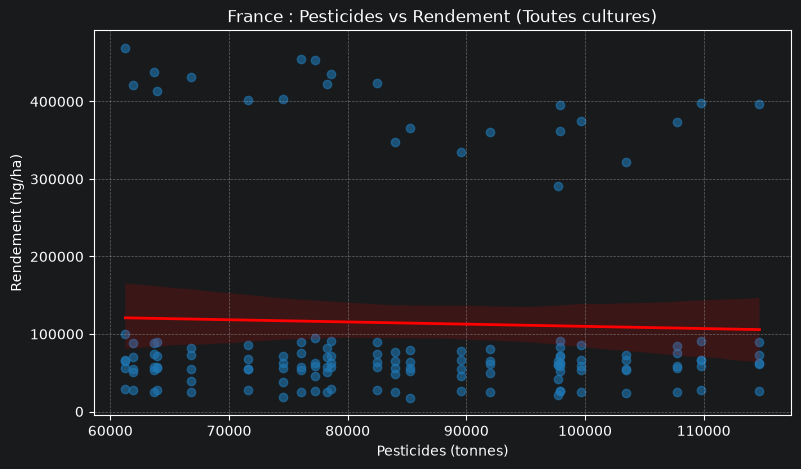

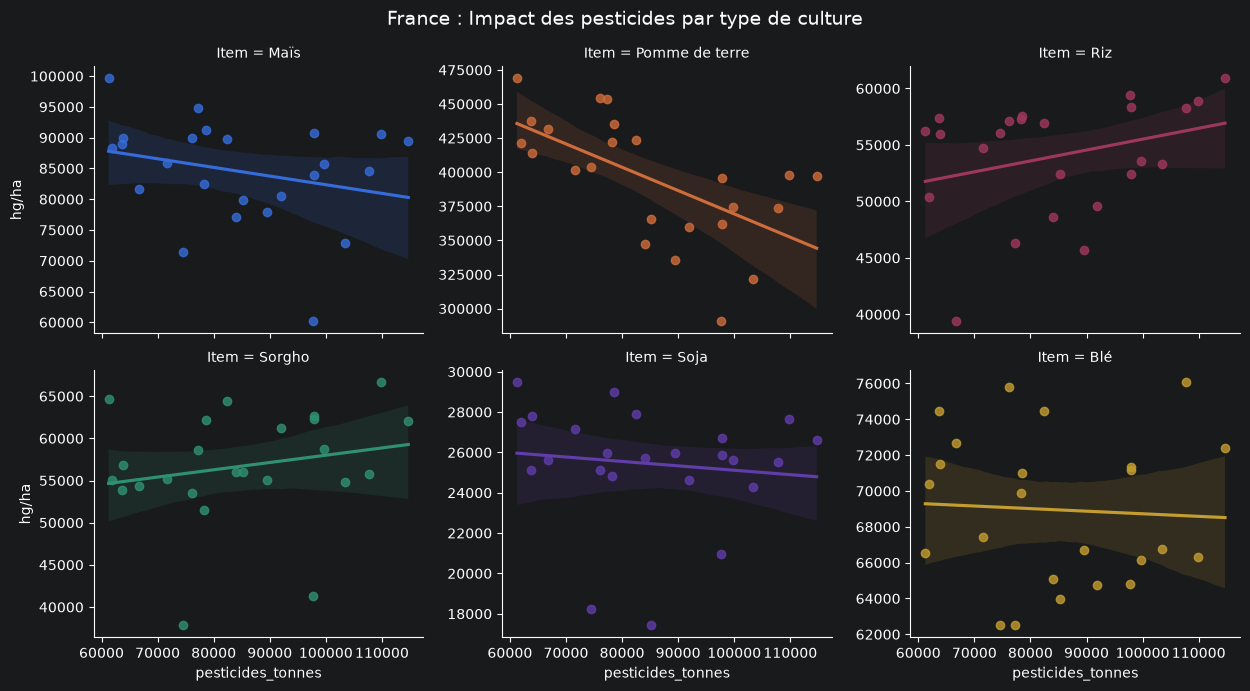

In [253]:
df_france = dataset[dataset['Area'] == 'France'].copy()

plt.figure(figsize=(9, 5))
sns.regplot(
    data=df_france,
    x='pesticides_tonnes',
    y='hg/ha',
    scatter_kws={'alpha': 0.6, 'color': '#1f77b4'},
    line_kws={'color': 'red', 'linewidth': 2}
)
plt.title('France : Pesticides vs Rendement (Toutes cultures)')
plt.xlabel('Pesticides (tonnes)')
plt.ylabel('Rendement (hg/ha)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

sns.lmplot(
    data=df_france,
    x='pesticides_tonnes',
    y='hg/ha',
    hue='Item',
    col='Item',
    col_wrap=3,
    height=3.5,
    aspect=1.2,
    facet_kws={'sharey': False},
)
plt.subplots_adjust(top=0.9)
plt.suptitle('France : Impact des pesticides par type de culture', fontsize=14)
plt.show()

Au sein de la France, aucune relation claire n'apparaît : la relation pesticides-rendement change même de signe selon la culture. Avec seulement 24 années, les deux variables suivent surtout leur propre tendance temporelle.

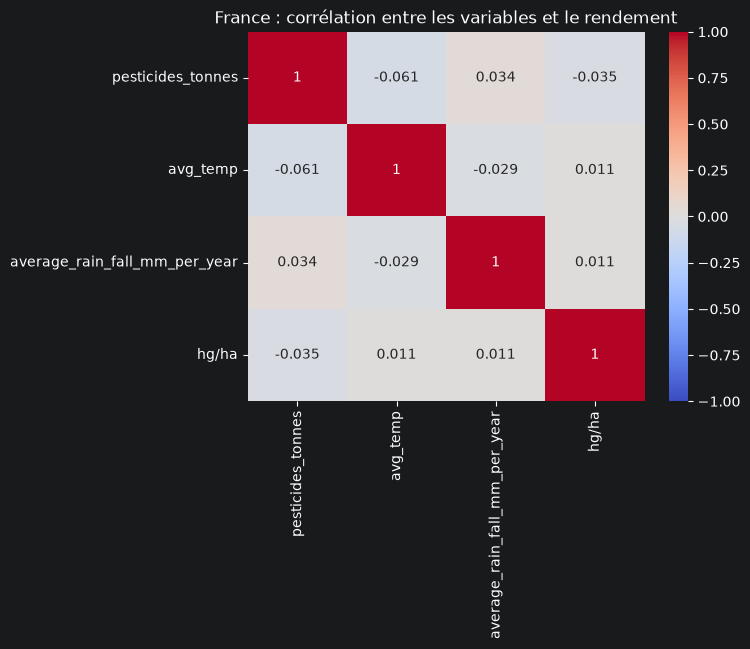

In [254]:
correlation = df_france[['pesticides_tonnes', 'avg_temp', 'average_rain_fall_mm_per_year', 'hg/ha']].corr()

# Graphique Heatmap
sns.heatmap(correlation, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('France : corrélation entre les variables et le rendement')
plt.show()

En France, les corrélations avec le rendement sont quasi nulles. Les variables climatiques n'ont qu'une valeur par pays et par an : elles distinguent bien les pays entre eux, mais varient trop peu dans un même pays pour expliquer le rendement d'une année sur l'autre.

In [270]:
# Calculer la médiane du rendement (ou du log du rendement) par pays
median_rendement_pays = (
    dataset_transformed.groupby('Area')['hg/ha'].median().reset_index()
)

# Trier du plus grand au plus petit
top_pays = median_rendement_pays.sort_values(by='hg/ha', ascending=False).head(
    10
)
flop_pays = median_rendement_pays.sort_values(by='hg/ha', ascending=True).head(
    10
)

print('--- TOP 10 des pays par rendement médian ---')
print(top_pays)

print('\n--- FLOP 10 des pays par rendement médian ---')
print(flop_pays)

--- TOP 10 des pays par rendement médian ---
                     Area     hg/ha
44           Cook Islands  260769.0
102                Kuwait  197301.5
198        United Kingdom  194192.0
197  United Arab Emirates  190476.0
94                Ireland  174106.0
20                Bermuda  173750.0
181                Sweden  170252.5
12                Bahrain  160000.0
97                Jamaica  156719.5
99                 Jordan  147569.0

--- FLOP 10 des pays par rendement médian ---
            Area    hg/ha
24      Botswana   3663.0
203      Vanuatu   5200.0
62       Eritrea   8124.5
107      Lesotho   8610.0
115     Maldives  11534.0
127   Mozambique  11680.5
175  South Sudan  11902.5
74        Gambia  12728.5
4         Angola  13719.5
126      Morocco  15182.5


## Conclusions

**Cible (rendement)**
- Distribution très asymétrique, expliquée principalement par la **culture** : les tubercules et plantains ont un rendement 5 à 10 fois supérieur aux céréales. `Item` est la variable la plus structurante, et la cible gagne à être passée au log.
- Le rendement moyen progresse sur 1990-2013 (≈ 60 000 → 77 000 hg/ha), avec de fortes différences selon les cultures.

**Features (corrélations avec log(rendement))**

- **Les corrélations globales sont faibles, mais deviennent nettes une fois les cultures séparées** : le mélange des cultures masque les relations.
- **Pesticides** : corrélation positive avec le rendement, surtout pour les céréales et le soja. Il s'agit d'une corrélation, pas d'un effet causal démontré : les pays qui utilisent beaucoup de pesticides sont aussi les plus mécanisés et les plus irrigués.
- **Température** : relation négative pour la plupart des cultures (maïs, blé, riz, sorgho), positive ou nulle pour le manioc et les ignames, des cultures tropicales. Cela traduit surtout des différences **entre pays** (climats tempérés vs tropicaux) plus qu'un effet de stress thermique.
- **Précipitations** : pas de relation globale ; l'effet est faible et change de signe selon la culture. Température et précipitations sont corrélées positivement : les pays chauds sont aussi plus pluvieux.
- **Focus France** : avec une seule valeur climatique par an et seulement 24 années, aucune corrélation n'est exploitable au sein d'un pays. Les variables climatiques expliquent surtout les écarts **entre** pays.